In [1]:
"""Schedule and automate periodic model retraining and validation using cron jobs or workflow orchestrators, ensuring models stay updated with new data and maintaining accuracy in changing environments."""

'Schedule and automate periodic model retraining and validation using cron jobs or workflow orchestrators, ensuring models stay updated with new data and maintaining accuracy in changing environments.'

In [2]:
# import libraries and load pharmacy sales dataset
import os
import json
import time
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

data_path = 'global_pharmacy_sales_data.csv' if os.path.exists('global_pharmacy_sales_data.csv') else '../global_pharmacy_sales_data.csv'
df = pd.read_csv(data_path)
print("pharmacy sales dataset loaded successfully. shape:", df.shape)

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\Lenovo\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


pharmacy sales dataset loaded successfully. shape: (177990, 14)


In [3]:
# clean dataset and prepare feature columns for modeling
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

sample_df = df.sample(n=6000, random_state=42).sort_values('date').reset_index(drop=True)
features = ['year', 'month', 'day', 'unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag']
target = 'units_sold'

print("selected modeling features:", features)
print("target variable:", target)
print("\nsample data summary:")
print(sample_df[features + [target]].describe().round(2))

selected modeling features: ['year', 'month', 'day', 'unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag']
target variable: units_sold

sample data summary:
          year    month      day  unit_price  stock_level  \
count  6000.00  6000.00  6000.00     6000.00      6000.00   
mean   2022.54     6.47    15.91       52.44      4553.92   
std       1.71     3.44     8.75       27.19       342.98   
min    2020.00     1.00     1.00        5.02         0.00   
25%    2021.00     3.00     8.00       29.17      4444.00   
50%    2023.00     6.00    16.00       51.99      4598.00   
75%    2024.00     9.00    23.00       75.49      4734.00   
max    2025.00    12.00    31.00       99.97      5076.00   

       expiry_days_remaining  covid_flag  units_sold  
count                6000.00     6000.00     6000.00  
mean                  373.67        0.32      447.11  
std                   200.74        0.47      334.89  
min                    30.00        0.00       76.00  
25% 

In [4]:
# split historical baseline and partition incoming periodic sales batches
train_baseline, stream_data = train_test_split(sample_df, test_size=0.4, shuffle=False)
val_holdout, streaming_pool = train_test_split(stream_data, test_size=0.6, shuffle=False)

batch_size = len(streaming_pool) // 2
batch_1 = streaming_pool.iloc[:batch_size].copy()
batch_2 = streaming_pool.iloc[batch_size:].copy()

os.makedirs('data_batches', exist_ok=True)
batch_1.to_csv('data_batches/batch_1.csv', index=False)
batch_2.to_csv('data_batches/batch_2.csv', index=False)
val_holdout.to_csv('data_batches/holdout_validation.csv', index=False)

print(f"baseline historical sales records: {len(train_baseline)}")
print(f"holdout validation benchmark records: {len(val_holdout)}")
print(f"incoming batch 1 records: {len(batch_1)}")
print(f"incoming batch 2 records: {len(batch_2)}")

baseline historical sales records: 3600
holdout validation benchmark records: 960
incoming batch 1 records: 720
incoming batch 2 records: 720


In [5]:
# define and train baseline pharmacy sales prediction model
X_train = train_baseline[features]
y_train = train_baseline[target]
X_val = val_holdout[features]
y_val = val_holdout[target]

baseline_model = RandomForestRegressor(n_estimators=60, max_depth=10, random_state=42, n_jobs=-1)
baseline_model.fit(X_train, y_train)

train_preds = baseline_model.predict(X_train)
val_preds = baseline_model.predict(X_val)

print("baseline pharmacy sales model training complete.")
print("training r2 score:", round(r2_score(y_train, train_preds), 4))

baseline pharmacy sales model training complete.


training r2 score: 0.9658


validation metrics on benchmark holdout:
mse: 5460.95
mae: 59.60
r2 score: 0.9482


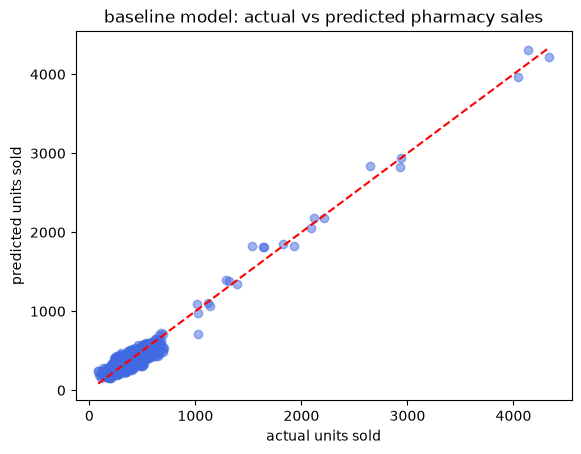

In [6]:
# evaluate baseline model and plot actual vs predicted sales demand
val_mse = mean_squared_error(y_val, val_preds)
val_mae = mean_absolute_error(y_val, val_preds)
val_r2 = r2_score(y_val, val_preds)

print("validation metrics on benchmark holdout:")
print(f"mse: {val_mse:.2f}")
print(f"mae: {val_mae:.2f}")
print(f"r2 score: {val_r2:.4f}")

plt.scatter(y_val, val_preds, color='royalblue', alpha=0.5)
plt.plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], 'r--')
plt.title('baseline model: actual vs predicted pharmacy sales')
plt.xlabel('actual units sold')
plt.ylabel('predicted units sold')
plt.show()

In [7]:
# save baseline model checkpoint and metadata registry
os.makedirs('model_registry', exist_ok=True)
initial_model_path = 'model_registry/pharmacy_model_v1.joblib'
joblib.dump(baseline_model, initial_model_path)

registry_metadata = {
    'active_version': 'v1.0',
    'active_model_path': initial_model_path,
    'training_samples': len(train_baseline),
    'validation_r2': float(val_r2),
    'validation_mse': float(val_mse),
    'last_updated': datetime.now().isoformat(),
    'history': [
        {
            'version': 'v1.0',
            'samples': len(train_baseline),
            'r2': float(val_r2),
            'mse': float(val_mse),
            'timestamp': datetime.now().isoformat(),
            'action': 'initial_deployment'
        }
    ]
}

with open('model_registry/metadata.json', 'w') as f:
    json.dump(registry_metadata, f, indent=4)

print("baseline model checkpoint and metadata saved in model_registry.")

baseline model checkpoint and metadata saved in model_registry.


In [8]:
# define automated retraining and validation pipeline function
def retrain_and_validate_pipeline(new_batch_path, current_cumulative_data, version_label):
    new_data = pd.read_csv(new_batch_path)
    updated_training_data = pd.concat([current_cumulative_data, new_data], ignore_index=True)
    
    X_updated = updated_training_data[features]
    y_updated = updated_training_data[target]
    
    candidate_model = RandomForestRegressor(n_estimators=60, max_depth=10, random_state=42, n_jobs=-1)
    candidate_model.fit(X_updated, y_updated)
    
    holdout_df = pd.read_csv('data_batches/holdout_validation.csv')
    X_holdout = holdout_df[features]
    y_holdout = holdout_df[target]
    
    candidate_preds = candidate_model.predict(X_holdout)
    cand_r2 = r2_score(y_holdout, candidate_preds)
    cand_mse = mean_squared_error(y_holdout, candidate_preds)
    
    with open('model_registry/metadata.json', 'r') as f:
        meta = json.load(f)
    
    current_best_r2 = meta['validation_r2']
    print(f"\n[validation check] candidate r2: {cand_r2:.4f} vs current r2: {current_best_r2:.4f}")
    
    if cand_r2 >= (current_best_r2 - 0.03):
        new_model_path = f'model_registry/pharmacy_model_{version_label}.joblib'
        joblib.dump(candidate_model, new_model_path)
        
        meta['active_version'] = version_label
        meta['active_model_path'] = new_model_path
        meta['training_samples'] = len(updated_training_data)
        meta['validation_r2'] = float(cand_r2)
        meta['validation_mse'] = float(cand_mse)
        meta['last_updated'] = datetime.now().isoformat()
        meta['history'].append({
            'version': version_label,
            'samples': len(updated_training_data),
            'r2': float(cand_r2),
            'mse': float(cand_mse),
            'timestamp': datetime.now().isoformat(),
            'action': 'promoted_to_production'
        })
        with open('model_registry/metadata.json', 'w') as f:
            json.dump(meta, f, indent=4)
        
        print(f"validation passed: promoted {version_label} to active production.")
        return candidate_model, updated_training_data, True, cand_r2
    else:
        print(f"validation failed: rejected {version_label}. retaining current production model.")
        return None, current_cumulative_data, False, cand_r2

In [9]:
# define workflow orchestrator and scheduled execution handler
class PharmacyRetrainingOrchestrator:
    def __init__(self, check_directory='data_batches'):
        self.check_directory = check_directory
        self.processed_files = set()
        
    def check_new_data_triggers(self):
        all_files = sorted(os.listdir(self.check_directory))
        new_batches = [
            f for f in all_files 
            if f.startswith('batch_') and f.endswith('.csv') and f not in self.processed_files
        ]
        return new_batches

    def run_scheduled_job(self, batch_file, current_data, cycle_number):
        batch_path = os.path.join(self.check_directory, batch_file)
        version_label = f"v{cycle_number + 1}.0"
        print(f"\n--- [orchestrator trigger] processing {batch_file} for cycle {cycle_number} ---")
        
        model, updated_data, status, score = retrain_and_validate_pipeline(
            batch_path, current_data, version_label
        )
        self.processed_files.add(batch_file)
        return updated_data, score

orchestrator = PharmacyRetrainingOrchestrator()
print("pharmacy retraining orchestrator initialized and ready to poll batch directory.")

pharmacy retraining orchestrator initialized and ready to poll batch directory.


In [10]:
# execute automated periodic retraining across incoming batches
cumulative_training = train_baseline.copy()
retraining_history = [('baseline_v1', len(cumulative_training), val_r2)]

available_triggers = orchestrator.check_new_data_triggers()
print("detected pending sales batches:", available_triggers)

for i, batch_file in enumerate(available_triggers, start=1):
    time.sleep(0.3)
    cumulative_training, score = orchestrator.run_scheduled_job(batch_file, cumulative_training, i)
    retraining_history.append((f'cycle_{i}', len(cumulative_training), score))

print("\nall periodic sales retraining workflows executed successfully.")

detected pending sales batches: ['batch_1.csv', 'batch_2.csv']



--- [orchestrator trigger] processing batch_1.csv for cycle 1 ---

[validation check] candidate r2: 0.9492 vs current r2: 0.9482
validation passed: promoted v2.0 to active production.



--- [orchestrator trigger] processing batch_2.csv for cycle 2 ---

[validation check] candidate r2: 0.9496 vs current r2: 0.9492
validation passed: promoted v3.0 to active production.

all periodic sales retraining workflows executed successfully.


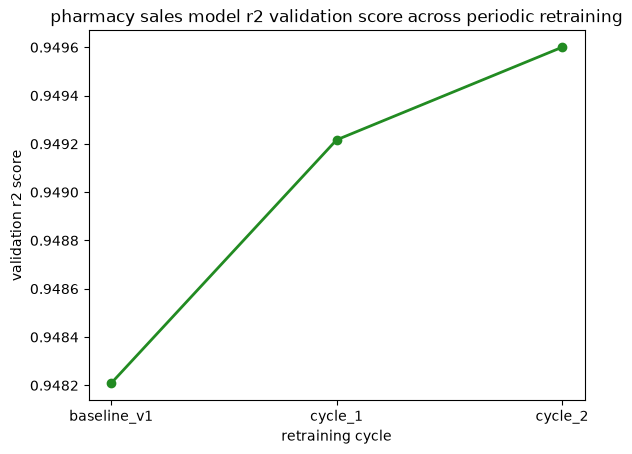

In [11]:
# plot model r2 score performance across retraining iterations
cycles = [item[0] for item in retraining_history]
scores = [item[2] for item in retraining_history]

plt.plot(cycles, scores, marker='o', color='forestgreen', linewidth=2)
plt.title('pharmacy sales model r2 validation score across periodic retraining')
plt.xlabel('retraining cycle')
plt.ylabel('validation r2 score')
plt.show()

In [12]:
# summary of periodic retraining results and current active model
with open('model_registry/metadata.json', 'r') as f:
    latest_meta = json.load(f)

summary_df = pd.DataFrame(latest_meta['history'])
print("automated pharmacy sales retraining audit log:")
print(summary_df[['version', 'samples', 'r2', 'mse', 'action']])
print("\ncurrent active model in production:", latest_meta['active_version'])
print("latest active model path:", latest_meta['active_model_path'])

automated pharmacy sales retraining audit log:
  version  samples        r2          mse                  action
0    v1.0     3600  0.948209  5460.947217      initial_deployment
1    v2.0     4320  0.949216  5354.679813  promoted_to_production
2    v3.0     5040  0.949600  5314.240696  promoted_to_production

current active model in production: v3.0
latest active model path: model_registry/pharmacy_model_v3.0.joblib
